# Day 3(M1 Day03) 실습 — Supervisor·Router 작업 분배

**목표**: 관리자(Supervisor)가 상황을 보고 다음 작업자를 정하는 그래프와, 입구에서 한 번 분류해 전문가에게 보내는 Router를 만들고 둘의 차이를 숫자로 비교한다.
## 오늘의 전체 그림

**오늘의 질문**: 다음 일은 누가 정하나? 매 단계 관리자가 정할까, 입구에서 한 번 분류할까?

```text
[Part 1 만든다]   TeamState(Day 2 인계서) · Decision 계약 · supervisor_node · 작업자 노드 3개 → StateGraph
      │           → 관리자가 매 단계 다음 작업자를 고른다
      ▼
[Part 2 바꿔보기]   build_team으로 관리자만 바꿔 끼운다 (요청 3종 · 허술한 관리자 · 최대 단계)
      │           → (확장) 순서 고정 run_fixed vs Supervisor: 호출 수·시간
      ▼
[Part 3 다르게 짠다] Router: classify → 상담원 4종 · 정확도 10문항 · 기준 보강
                  → (확장) 유형 추가 complaint와 회귀 확인
```

| Part | 블록 | 답하는 질문 | 다음 Part로 넘기는 것 |
| --- | --- | --- | --- |
| Part 1 | 따라 하기 | 관리자가 다음 작업자를 고르게 하려면? | `TeamState` · `supervisor_node` · 작업자 노드 · `route_next` |
| Part 2 | 바꿔 보기 | 관리자의 품질과 비용은 무엇이 좌우하나? | Supervisor의 유연함과 대가 (호출 수) |
| Part 3 | 미니 프로젝트 | 담당이 고정된 일은 어떻게 나누나? | Router 봇 · 분류 기준 → Day 4 병렬 분배 |

> 💡 Part 1·2는 같은 리서치 팀을 쓰고, Part 3은 새 봇을 만든다. Part 3은 Part 1의 그래프 조립 방법(노드·조건 엣지)을 그대로 쓴다.

> 💡 StateGraph·조건 엣지·재귀 한도(`recursion_limit`)는 **2과목 Day 14**에서 배웠다. 오늘 새로운 것은 "다음 경로를 **LLM 관리자가** 정한다"는 점이다.

## 0. 환경 준비 — Day 2 팀 불러오기

> 💡 오늘부터 흐름 제어를 **LangGraph**(`StateGraph`)가 맡는다. Day 2에서 함수가 손으로 넘기던 인계서가 `TeamState`가 되고, 그래프가 노드 사이로 자동으로 나른다. 노드 안의 모델 호출은 그대로 LangChain이다.

Day 2에서 만든 계약 3종과 에이전트 3종을 그대로 쓴다. Day 2의 교훈(원문을 못 받은 검토자는 빠진 사실을 모른다)대로 **검토자에게 원문도 넘긴다**.

In [6]:
import os

# 추적 끄기: 2과목 Day17에서 .env의 LANGSMITH_TRACING을 켰다면 오늘 호출이 전부 전송된다
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"

import time
from typing import Literal

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field
from typing_extensions import TypedDict

load_dotenv()

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.9)  # 생성 역할
llm_strict = ChatOpenAI(model="gpt-4o-mini", temperature=0)  # 판정·결정 역할

SOURCE = """[내부 소개 자료] 달빛 도서관
달빛 도서관은 밤 10시부터 새벽 2시까지 여는 무인 야간 도서관이다.
서울 마포구에 1호점이 있으며, 좌석은 총 48석이다.
입장은 월 구독제이며, 구독료는 월 19,900원이다.
사서 대신 안내 로봇 '루나'가 책 추천과 반납을 돕는다.
조용한 환경을 위해 통화와 취식은 금지된다.
회원의 62%가 20~30대 직장인이다.
2026년 12월에 부산 2호점이 문을 열 예정이다."""

print("준비 완료:", llm.model_name)

준비 완료: gpt-4o-mini


In [7]:
# --- Day 2 계약 3종 ---
class ResearchNotes(BaseModel):
    facts: list[str] = Field(description="원문에서 뽑은 핵심 사실 5개. 각 사실은 한 문장.")


class Draft(BaseModel):
    title: str = Field(description="소개 글 제목")
    body: str = Field(description="사실에 근거한 소개 단락 (3~4문장)")


class Review(BaseModel):
    passed: bool = Field(description="원문과 일치하고 지어낸 내용이 없으면 True")
    missing_facts: list[str] = Field(description="초안에 빠졌거나 왜곡된 사실 목록")
    comments: str = Field(description="한 줄 총평")


# --- Day 2 에이전트 3종 (짧게 줄인 버전) ---
def researcher_agent(source):
    prompt = f"당신은 조사원입니다. 새 정보를 지어내지 마세요.\n다음 원문에서 핵심 사실 5개를 뽑으세요.\n\n[원문]\n{source}"
    return llm.with_structured_output(ResearchNotes).invoke(prompt)


def writer_agent(facts):
    facts_text = "\n".join(f"- {f}" for f in facts)
    prompt = f"당신은 작성자입니다. 사실에 없는 내용을 추가하지 마세요.\n\n[사실]\n{facts_text}\n\n위 사실로 소개 글을 쓰세요. 본문 3~4문장."
    return llm.with_structured_output(Draft).invoke(prompt)


def reviewer_agent(source, facts, draft):
    facts_text = "\n".join(f"- {f}" for f in facts)
    prompt = f"당신은 검토자입니다. 직접 고치지 마세요.\n\n[원문]\n{source}\n\n[조사원의 사실]\n{facts_text}\n\n[초안]\n제목: {draft.title}\n본문: {draft.body}\n\n초안이 원문과 일치하는지 판정하세요."
    return llm_strict.with_structured_output(Review).invoke(prompt)


print("Day 2 팀 준비 완료")

Day 2 팀 준비 완료


## Part 1. 따라 하기 — Supervisor 그래프

**전체 그림 1/3**: Day 2의 인계서를 `TeamState`로 옮기고, 관리자가 다음 작업자를 고르는 그래프를 만든다 → Part 2가 관리자만 바꿔 끼운다.

### 1-1. TeamState — Day 2 인계서가 그래프의 State가 된다

Day 2에서는 인계서(`Handoff`)를 손으로 넘겼다. 오늘은 **LangGraph가 나른다**. 칸도 거의 같다.

| Day 2 인계서 | 오늘 TeamState | 채우는 쪽 |
| --- | --- | --- |
| `request`, `source` | `request`, `source` | 시작할 때 |
| `facts` | `facts` | 조사원 |
| `title`, `body` | `draft_title`, `draft_body` | 작성자 |
| `passed`, `comments` | `review_done`, `review_passed`, `review_comments` | 검토자 |
| `log` | `log` | 모두 |
| — | `next` | **관리자** (새로 생긴 칸) |

> 💡 검토 완료 여부는 `review_done` **플래그**로 기록한다. 내용(comments)이 있는지로 판정하면, 내용이 빈 문자열일 때 "안 했다"로 오판한다 (Day 2 3-3에서 실제로 총평이 빈 문자열이었다).

In [8]:
class TeamState(TypedDict):
    request: str  # 사용자 요청
    source: str  # 원문 자료
    facts: list[str]  # 조사원의 산출물
    draft_title: str  # 작성자의 산출물
    draft_body: str
    review_done: bool  # 검토 완료 플래그 (내용이 아니라 플래그로 기록)
    review_passed: bool
    review_comments: str
    # TODO: 관리자의 결정 next(문자열)와 호출 기록 log(문자열 리스트) 칸을 추가하세요
    log: list[str] # 에이전트 호출 기록

print("TeamState 정의 완료")

TeamState 정의 완료


### 1-2. 결정 계약과 상황 보고

관리자는 ① 상황 체크리스트를 보고 ② 결정 절차를 따라 ③ `Decision` 계약으로 답한다.

<details>
<summary>설계 포인트 (사전 검증에서 얻은 교훈)</summary>

- **체크리스트 상황 보고**: "사실 확보됨"처럼 뭉뚱그리면 관리자가 "초안도 있겠지"라고 착각한다 → 산출물마다 있음/없음을 적는다.
- **필드 순서 = 생각 순서**: `final_goal` → `satisfied` → `next` 순으로 두면 목표를 먼저 확인하고 결정한다.
- **`Literal`**: 정해진 값(`researcher`·`writer`·`reviewer`·`done`)만 고르게 막는다 → 없는 작업자 이름이 나오지 않는다.
</details>

In [9]:
class Decision(BaseModel):
    """관리자의 결정 계약 — 필드 순서가 곧 생각 순서다"""

    final_goal: str = Field(description="사용자 요청이 요구하는 마지막 산출물 (예: 사실 목록, 초안, 검토 판정)")

    # TODO: satisfied 필드를 만드세요 — "이미 충족됐는가"(True/False), description은 "그 산출물이 현재 상황에 이미 있으면 True"
    satisfied:bool = Field(description="그 산출물이 현재 상황에 이미 있으면 True")

    next: Literal["researcher", "writer", "reviewer", "done"] = Field(
        description="satisfied가 True면 반드시 done. 아니면 선행 조건이 갖춰진 다음 한 명."
    )
    reason: str = Field(description="그렇게 정한 이유 한 줄")

In [11]:
def summarize_state(state):
    """산출물별 있음/없음 체크리스트 — 관리자가 착각하지 않도록 명시한다"""
    if state.get("facts"):
        facts = f"있음 ({len(state['facts'])}개)"
    else:
        facts = "없음"

    if state.get("draft_body"):
        draft = "있음"
    else:
        draft = "없음"

    if state.get("review_done"):
        review = f"있음 (통과={state['review_passed']})"
    else:
        review = "없음"

    return f"- 사실 목록: {facts}\n- 초안: {draft}\n- 검토 판정: {review}"


print(summarize_state({"facts": ["a", "b"]}))

- 사실 목록: 있음 (2개)
- 초안: 없음
- 검토 판정: 없음


### 1-3. Supervisor 노드

> 💡 **최대 단계(`MAX_STEPS`)**: 관리자가 헤매면 무한 반복한다. 2과목 Day 14에서 본 재귀 한도(기본 25)에 걸려 **오류로** 멈추기 전에, 우리가 정한 단계에서 **정상 종료**시킨다.

In [12]:
MAX_STEPS = 8

def supervisor_node(state):
    log = state.get("log", [])
    if len(log) >= MAX_STEPS:
        return {"next": "done", "log": log + ["supervisor: 최대 단계 도달 → 강제 종료"]}

    prompt = f"""당신은 리서치 팀의 관리자(Supervisor)입니다.

[사용자 요청] {state["request"]}

[현재 상황 — 산출물 체크리스트]
{summarize_state(state)}

팀원과 임무:
- researcher: 원문에서 핵심 사실 추출 → 산출물: 사실 목록
- writer: 사실로 소개 글 작성 → 산출물: 초안 (선행 조건: 사실 목록)
- reviewer: 초안과 원문 대조 → 산출물: 검토 판정 (선행 조건: 초안)

결정 절차:
1. 요청이 요구하는 마지막 산출물(final_goal)을 정한다.
2. 체크리스트에서 그 산출물이 "있음"인 경우에만 satisfied=True, next=done.
3. "없음"이면 선행 조건이 갖춰진 다음 한 명을 next로 정한다.
4. 요청에 필요 없는 산출물은 만들지 않는다 (최소한의 역할만 부른다)."""

    # TODO: 판정용 모델(llm_strict)에 Decision 계약을 걸어 prompt를 호출하고 결과를 d에 담으세요
    d = llm_strict.with_structured_output(Decision).invoke(prompt)

    return {"next": d.next, "log": log + [f"supervisor → {d.next} ({d.reason})"]}

print("Supervisor 노드 준비 완료")

Supervisor 노드 준비 완료


### 1-4. 작업자 노드 — Day 2 에이전트 감싸기

노드 함수 = state 읽기 → 에이전트 호출 → state 갱신 + 로그.

> ⚠️ 관리자의 결정은 100%가 아니다. 초안이 없는데 reviewer를 부르면 프로그램이 죽는다 (사전 검증에서 KeyError) → 노드가 선행 조건을 **방어**한다. Day 2 3-8의 "받을 때 확인하기"와 같은 원칙이다.

In [13]:
def researcher_node(state):
    notes = researcher_agent(state["source"])
    return {"facts": notes.facts, "log": state["log"] + ["researcher: 사실 추출 완료"]}


def writer_node(state):
    # TODO: 사실 목록(facts)이 없으면 작성하지 말고
    #       {"log": state["log"] + ["writer: 사실이 없어 작성 불가 → 관리자에게 되돌림"]}을 반환하세요
    if not state.get("facts"):
        return {"log":state["log"] + ["writer: 사실이 없어 작성 불가 → 관리자에게 되돌림"]}
    draft = writer_agent(state["facts"])
    return {"draft_title": draft.title, "draft_body": draft.body, "log": state["log"] + ["writer: 초안 작성 완료"]}


def reviewer_node(state):
    # TODO: 초안 본문(draft_body)이 없으면 검토하지 말고
    #       {"log": state["log"] + ["reviewer: 초안이 없어 검토 불가 → 관리자에게 되돌림"]}을 반환하세요
    if not state.get("draft_body"):
        return {"log":state["log"] + ["reviewer: 초안이 없어 검토 불가 → 관리자에게 되돌림"]}
    
    draft = Draft(title=state["draft_title"], body=state["draft_body"])
    review = reviewer_agent(state["source"], state["facts"], draft)
    return {
        "review_done": True,
        "review_passed": review.passed,
        "review_comments": review.comments,
        "log": state["log"] + ["reviewer: 검토 완료"],
    }


print("작업자 노드 3개 준비 완료")

작업자 노드 3개 준비 완료


### 1-5. 그래프 조립·실행

```text
START → supervisor → (조건 엣지: next 값) → 작업자 → supervisor → ... → done → END
```

작업자는 일이 끝나면 **항상 관리자에게 돌아간다** → 관리자가 매번 상황을 다시 보고 다음을 정한다.

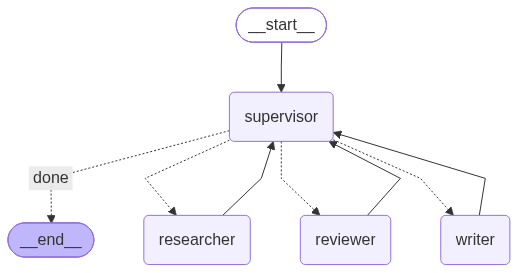

In [14]:
def route_next(state):
    """조건 엣지: 관리자가 적어 둔 next 값을 그대로 돌려준다"""
    return state["next"]


graph = StateGraph(TeamState)
graph.add_node("supervisor", supervisor_node)
graph.add_node("researcher", researcher_node)
graph.add_node("writer", writer_node)
graph.add_node("reviewer", reviewer_node)

graph.add_edge(START, "supervisor")
# TODO: supervisor 노드에 조건 엣지를 추가하세요 — route_next가 돌려준 값에 따라
#       researcher · writer · reviewer 노드로 가고, "done"이면 END로 간다
graph.add_conditional_edges("supervisor", route_next, {"researcher":"researcher", "writer":"writer", "reviewer":"reviewer", "done" : END})

# TODO: 작업자 3명이 일을 끝내면 누구에게 돌아가야 할까요? 엣지 3개를 추가하세요
graph.add_edge("researcher", "supervisor")
graph.add_edge("writer", "supervisor")
graph.add_edge("reviewer", "supervisor")

team = graph.compile()
team

In [15]:
result = team.invoke({"request": "소개 글을 쓰고 검토까지 해줘", "source": SOURCE, "log": []})
print("[호출 로그]")
for line in result["log"]:
    print(" ", line)
print("\n[초안 제목]", result.get("draft_title"))
print("[검토 통과]", result.get("review_passed"))

[호출 로그]
  supervisor → researcher (소개 글 작성을 위해서는 먼저 원문에서 핵심 사실을 추출해야 하므로, 사실 목록이 필요하다. 따라서 researcher에게 사실 목록 작성을 지시해야 한다.)
  researcher: 사실 추출 완료
  supervisor → writer (사실 목록이 있으나 초안이 없으므로, writer가 초안을 작성해야 함.)
  writer: 초안 작성 완료
  supervisor → reviewer (초안이 있으나 검토 판정이 필요하기 때문입니다. 검토자가 초안을 대조하여 검토 판정을 내려야 합니다.)
  reviewer: 검토 완료
  supervisor → done (모든 산출물이 준비되어 있으며 검토 판정도 통과하였기 때문에 요청을 완료할 수 있습니다.)

[초안 제목] 달빛 도서관 소개
[검토 통과] True


**관찰 포인트**: 로그에서 관리자가 몇 번 결정했는가? 결정마다 남긴 이유(reason)가 체크리스트와 맞는가?

## Part 2. 바꿔 보기 — 동적 분배·관리자 품질·안전장치

**전체 그림 2/3**: Part 1의 작업자 노드는 그대로 두고 관리자 함수만 바꿔 실험한다 → 유연함의 대가(호출 수)가 Part 3의 Router를 고르는 근거가 된다.

관리자 함수를 바꿔 끼울 수 있도록 팀 조립을 함수 하나로 묶는다 (Day 1 3-5처럼 **함수를 인자로** 넘긴다).

In [16]:
def build_team(supervisor_fn):
    """관리자 함수를 바꿔 끼울 수 있는 팀 조립기"""
    g = StateGraph(TeamState)
    g.add_node("supervisor", supervisor_fn)
    g.add_node("researcher", researcher_node)
    g.add_node("writer", writer_node)
    g.add_node("reviewer", reviewer_node)
    g.add_edge(START, "supervisor")
    g.add_conditional_edges(
        "supervisor",
        route_next,
        {"researcher": "researcher", "writer": "writer", "reviewer": "reviewer", "done": END},
    )
    g.add_edge("researcher", "supervisor")
    g.add_edge("writer", "supervisor")
    g.add_edge("reviewer", "supervisor")
    return g.compile()


team = build_team(supervisor_node)
print("팀 조립기 준비 완료")

팀 조립기 준비 완료


### 2-1. 요청 3종 — 동적 분배

같은 팀에 요청 세 개를 넣고 호출 로그를 비교한다.

> ⚠️ 이 셀은 LLM을 10번 안팎 호출한다 (1~2분).

In [17]:
REQUESTS = [
    "원문에서 핵심 사실만 정리해줘",
    "소개 글 초안까지만 만들어줘",
    "소개 글을 쓰고 검토까지 해줘",
]

for req in REQUESTS:
    print(f"\n[요청] {req}")
    # TODO: 요청(req)과 원문(SOURCE), 빈 로그를 넣어 team을 실행하고 결과를 result에 담으세요
    result = team.invoke({"request": req, "source":SOURCE, "log":[]})

    for line in result["log"]:
        print(" ", line)


[요청] 원문에서 핵심 사실만 정리해줘
  supervisor → researcher (원문에서 핵심 사실을 추출해야 하므로 researcher가 필요하다.)
  researcher: 사실 추출 완료
  supervisor → done (사실 목록이 이미 존재하므로 요청된 최종 산출물이 충족됨.)

[요청] 소개 글 초안까지만 만들어줘
  supervisor → researcher (소개 글 초안 작성을 위해서는 먼저 사실 목록이 필요하기 때문에, researcher에게 사실 목록을 추출하도록 지시해야 합니다.)
  researcher: 사실 추출 완료
  supervisor → writer (사실 목록이 있으므로 writer에게 초안 작성을 지시해야 함.)
  writer: 초안 작성 완료
  supervisor → reviewer (초안이 있지만 검토 판정이 필요하기 때문에 다음 단계로 reviewer에게 진행해야 함.)
  reviewer: 검토 완료
  supervisor → done (초안이 이미 존재하고 검토 판정도 통과했기 때문에 요청된 최종 산출물이 충족되었다.)

[요청] 소개 글을 쓰고 검토까지 해줘
  supervisor → researcher (소개 글 작성을 위해서는 먼저 원문에서 핵심 사실을 추출해야 하므로, 사실 목록이 필요하다. 따라서 researcher에게 사실 목록 작성을 지시해야 한다.)
  researcher: 사실 추출 완료
  supervisor → writer (사실 목록이 있으나 초안이 없으므로, writer에게 초안을 작성하도록 지시해야 함.)
  writer: 초안 작성 완료
  supervisor → reviewer (초안이 있으나 검토 판정이 필요하기 때문에, 리뷰어가 초안을 검토해야 함.)
  reviewer: 검토 완료
  supervisor → done (모든 산출물이 준비되어 있으며 검토 판정도 통과하였기 때문에 요청을 완료할 수 있습니다.)


**관찰 포인트**: 같은 코드인데 요청에 따라 일한 작업자 수가 달라졌는가? 관리자가 필요 없는 역할을 부른 경우가 있는가?

### 2-2. 허술한 관리자 — 프롬프트도 설계다

상황 보고를 뭉뚱그리고 결정 절차를 없앤 "허술한 관리자"로 바꿔 실행한다.

In [19]:
def supervisor_vague(state):
    """허술한 관리자: 뭉뚱그린 상황 보고 + 절차 없는 결정"""
    log = state.get("log", [])
    if len(log) >= MAX_STEPS:
        return {"next": "done", "log": log + ["supervisor: 최대 단계 도달 → 강제 종료"]}

    done_things = []
    if state.get("facts"):
        done_things.append("사실 확보됨")
    if state.get("draft_body"):
        done_things.append("초안 있음")
    if state.get("review_done"):
        done_things.append("검토됨")
    situation = ", ".join(done_things)
    if not done_things:
        situation = "아직 아무것도 없음"

    prompt = f"""당신은 팀 관리자입니다. 팀원: researcher(사실 추출), writer(글 작성), reviewer(검토).
요청이 끝났으면 done을 고르세요.

[요청] {state["request"]}
[상황] {situation}

다음에 일할 팀원을 정하세요."""
    d = llm_strict.with_structured_output(Decision).invoke(prompt)
    return {"next": d.next, "log": log + [f"supervisor → {d.next} ({d.reason})"]}

In [20]:
team_vague = build_team(supervisor_vague)
for i in range(2):
    result = team_vague.invoke({"request": "소개 글을 쓰고 검토까지 해줘", "source": SOURCE, "log": []})
    print(f"\n[{i + 1}회] 검토 완료: {result.get('review_done', False)}")
    for line in result["log"]:
        print(" ", line)


[1회] 검토 완료: False
  supervisor → researcher (소개 글을 작성하기 위해서는 먼저 필요한 정보를 추출해야 하므로 researcher가 필요합니다.)
  researcher: 사실 추출 완료
  supervisor → done (사실이 확보되어 있어 글 작성과 검토가 가능하기 때문입니다.)

[2회] 검토 완료: False
  supervisor → researcher (소개 글을 작성하기 위해서는 먼저 필요한 정보를 추출해야 하므로 researcher가 필요합니다.)
  researcher: 사실 추출 완료
  supervisor → done (사실이 확보되어 있어 글 작성과 검토가 가능하다.)


**관찰 포인트**: 허술한 관리자는 "검토까지" 요청을 끝까지 수행했는가? 어디서 틀렸는가?

| 실패 (사전 검증에서 관찰) | 증상 | 해결 |
| --- | --- | --- |
| 선행 조건 무시 | 초안이 없는데 reviewer 호출 | 작업자 노드의 방어 코드 |
| 같은 역할 반복 | writer를 계속 호출 → 강제 종료 | 결정 절차 + `satisfied` 필드 |
| 조기 종료 | "사실이 있으니 끝났다"고 착각하고 done | 체크리스트 상황 보고 |

### 2-3. 안전장치 — 최대 단계 줄이기

최대 단계를 4로 줄이면, 로그 6줄이 필요한 "검토까지" 요청은 중간에 멈춘다.

In [21]:
def supervisor_limited(state):
    """최대 단계를 4로 줄인 관리자 (그 외는 정상과 같다)"""
    log = state.get("log", [])
    if len(log) >= 4:
        return {"next": "done", "log": log + ["supervisor: 최대 단계(4) 도달 → 강제 종료"]}
    return supervisor_node(state)


team_limited = build_team(supervisor_limited)
result = team_limited.invoke({"request": "소개 글을 쓰고 검토까지 해줘", "source": SOURCE, "log": []})
for line in result["log"]:
    print(" ", line)
print("\n검토 완료 여부:", result.get("review_done", False))

  supervisor → researcher (소개 글 작성을 위해서는 먼저 원문에서 핵심 사실을 추출해야 하므로, 사실 목록이 필요하다. 따라서 researcher에게 사실 목록 작성을 지시해야 한다.)
  researcher: 사실 추출 완료
  supervisor → writer (사실 목록이 있으나 초안이 없으므로, writer에게 초안을 작성하도록 지시해야 함.)
  writer: 초안 작성 완료
  supervisor: 최대 단계(4) 도달 → 강제 종료

검토 완료 여부: False


**관찰 포인트**: 안전장치는 "일을 다 못 해도 폭주는 막는" 장치다. 한도는 정상 작업이 끝날 만큼 넉넉히, 무한 반복은 막을 만큼 짧게 잡는다 (M2 운영의 재시도 상한에서 같은 감각이 다시 나온다).

## Part 2-확장. 유연함의 대가 — 호출 수와 시간

관리자는 요청마다 팀을 다르게 움직인다. 그 대신 **결정할 때마다 LLM을 한 번 더** 부른다.
같은 "검토까지" 요청을 Day 2 방식(순서 고정)과 Supervisor 방식으로 각각 3번 실행해 비교한다.

> ⚠️ 이 셀은 LLM을 30번 안팎 호출한다 (2~3분).

In [ ]:
def run_fixed(source):
    """Day 2 방식: 조사 → 작성 → 검토 순서 고정 (결정 호출 없음)"""
    notes = researcher_agent(source)
    draft = writer_agent(notes.facts)
    reviewer_agent(source, notes.facts, draft)
    return 3  # LLM 호출 수: 작업자 3번


fixed_calls = []
fixed_secs = []
sup_calls = []
sup_secs = []

for i in range(3):
    start = time.perf_counter()
    fixed_calls.append(run_fixed(SOURCE))
    fixed_secs.append(time.perf_counter() - start)

    start = time.perf_counter()
    result = team.invoke({"request": "소개 글을 쓰고 검토까지 해줘", "source": SOURCE, "log": []})
    sup_secs.append(time.perf_counter() - start)
    sup_calls.append(len(result["log"]))  # 로그 한 줄 = LLM 호출 한 번 (결정 + 작업)

print("순서 고정  — LLM 호출:", fixed_calls, "/ 평균 시간:", round(sum(fixed_secs) / 3, 1), "초")
print("Supervisor — LLM 호출:", sup_calls, "/ 평균 시간:", round(sum(sup_secs) / 3, 1), "초")

**관찰 포인트**: 같은 결과를 내는 데 호출 수와 시간이 몇 배 들었는가? 순서가 항상 같은 작업이라면 관리자가 필요한가?

## Part 3. 미니 프로젝트 — 고객 문의 라우팅 봇

**전체 그림 3/3**: 입구에서 한 번만 분류하는 Router를 만든다 → Part 1과 같은 조립 방법(노드·조건 엣지)으로 구조만 다르게 짠다.

문의 유형 4종을 **입구에서 한 번** 분류해 전문 상담원에게 보낸다. Supervisor와 달리 되돌아오지 않는다.

| 유형 | 전문 상담원 |
| --- | --- |
| order | 주문·배송 상담원 |
| refund | 환불·교환 상담원 |
| usage | 기술지원 상담원 |
| etc | 일반 상담원 |

### 3-1. 분류 계약과 분류기 (v1)

유형은 `Literal` 계약으로 고정한다 → 네 가지 말고는 나올 수 없다.

In [31]:
class RouteDecision(BaseModel):
    # TODO: category 필드를 만드세요 — 네 가지 유형(order, refund, usage, etc)만 허용하는 Literal, description은 "문의 유형"
    category: Literal["order", "refund", "usage", "etc"] = Field(description="문의 유형")

CATEGORY_GUIDE_V1 = """- order: 주문·배송 관련 (배송 조회, 도착 예정, 주문 변경·옵션)
- refund: 환불·교환 관련 (환불, 결제 취소, 파손 교환)
- usage: 제품 사용법·고장 관련 (작동법, 연결, 오류)
- etc: 그 외 (매장, 회원, 일반 문의)"""


def classify(question, guide):
    prompt = f"""당신은 고객 문의 분류기입니다. 문의를 하나의 유형으로 분류하세요.

유형:
{guide}

[문의] {question}"""
    # TODO: llm_strict에 RouteDecision 계약을 걸어 prompt를 호출하고 결과를 decision에 담으세요
    decision = llm_strict.with_structured_output(RouteDecision).invoke(prompt)
    return decision.category

In [32]:
for q in ["주문한 상품이 언제 도착하나요?", "어제 산 제품 환불하고 싶어요", "전원이 안 켜져요"]:
    print(classify(q, CATEGORY_GUIDE_V1), "←", q)

order ← 주문한 상품이 언제 도착하나요?
refund ← 어제 산 제품 환불하고 싶어요
usage ← 전원이 안 켜져요


### 3-2. 전문 상담원 4종

각 상담원은 자기 분야의 정책(모의)을 가진다. 역할 정의서 원칙(Day 2)대로 "하지 않는 일"까지 담는다.

In [24]:
SPECIALISTS = {
    "order": "당신은 주문·배송 담당 상담원입니다. 배송은 결제 후 2~3일 걸립니다. 배송 조회는 마이페이지 > 주문내역에서 합니다. 환불·기술 문의에는 답하지 않습니다.",
    # TODO: "refund" 항목을 추가하세요 — 환불·교환 상담원의 역할 정의 (정책 2가지 + 하지 않는 일)
    "refund":"환불·교환 상담원의 역할 정의 (정책 2가지 + 하지 않는 일)",
    "usage": "당신은 제품 기술지원 상담원입니다. 전원 문제는 5초 이상 길게 눌러 재시작을 안내합니다. 앱 연결은 블루투스 설정에서 기기명을 선택합니다. 주문·환불 문의에는 답하지 않습니다.",
    "etc": "당신은 일반 문의 상담원입니다. 매장은 평일 10~20시 운영입니다. 회원 등급은 구매 금액에 따라 자동 조정됩니다.",
}

In [26]:
def answer_as(category, question):
    """category 담당 상담원으로서 두 문장 이내로 답한다."""
    system = SPECIALISTS[category] + " 두 문장 이내로 답하세요."
    
    return llm_strict.invoke([("system", system), ("human", question)]).content.strip()

print(answer_as("usage", "전원이 안 켜져요"))

전원 버튼을 5초 이상 길게 눌러 재시작해 보세요. 그래도 문제가 해결되지 않으면 추가 지원을 요청해 주세요.


### 3-3. Router 그래프 조립

```text
START → classify → (조건 엣지: category 값) → 전문 상담원 노드 → END
```

In [28]:
class BotState(TypedDict):
    question: str
    category: str
    answer: str

# 라우터를 위한 분류 노드
def classify_node(state):
    # TODO: state의 문의(question)를 CATEGORY_GUIDE_V1 기준으로 classify해 {"category": 분류 결과}로 반환하세요
    return {"category": classify(state["question"], CATEGORY_GUIDE_V1)}

# 주문 질문 노드
def order_node(state):
    return {"answer": answer_as("order", state["question"])}

# 환불 담당 노드
def refund_node(state):
    return {"answer": answer_as("refund", state["question"])}

# 사용법 담당 노드
def usage_node(state):
    return {"answer": answer_as("usage", state["question"])}

# 기타요청 담당 노드(폴백)
def etc_node(state):
    return {"answer": answer_as("etc", state["question"])}

# 라우터
def route_category(state):
    return state["category"]

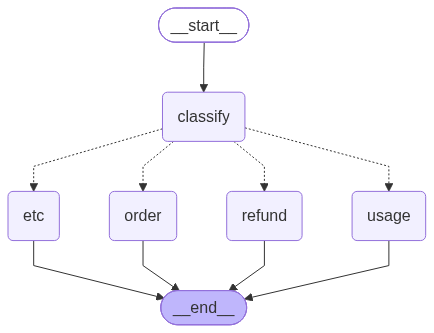

In [30]:
g = StateGraph(BotState)
g.add_node("classify", classify_node)
g.add_node("order", order_node)
g.add_node("refund", refund_node)
g.add_node("usage", usage_node)
g.add_node("etc", etc_node)

g.add_edge(START, "classify")
g.add_conditional_edges(
    "classify",
    route_category,
    {"order": "order", "refund": "refund", "usage": "usage", "etc": "etc"},
)
# TODO: 상담원은 답하면 끝입니다. 상담원 노드 4개(order · refund · usage · etc)를 어디로 연결할지 엣지 4개를 추가하세요
g.add_edge("order", END)
g.add_edge("refund", END)
g.add_edge("usage", END)
g.add_edge("etc", END)
bot = g.compile()
bot

# print("라우팅 봇 조립 완료")

### 3-4. 시연

In [33]:
for q in ["받은 물건이 파손됐어요. 새것으로 바꿔주세요", "전원이 안 켜져요"]:
    r = bot.invoke({"question": q})
    print("[문의]", q)
    print("[분류]", r["category"])
    print("[답변]", r["answer"])
    print()

[문의] 받은 물건이 파손됐어요. 새것으로 바꿔주세요
[분류] refund
[답변] 환불·교환 상담원은 고객의 요청에 따라 파손된 물건의 교환 절차를 안내하고, 필요한 경우 환불 정책에 대해 설명합니다. 그러나 상담원은 직접 물품을 교환하거나 환불을 처리하지 않습니다.

[문의] 전원이 안 켜져요
[분류] usage
[답변] 전원 버튼을 5초 이상 길게 눌러 재시작해 보세요. 그래도 문제가 해결되지 않으면 추가 지원을 요청해 주세요.



### 3-5. 분류 정확도 평가 — 10문항

정답 라벨이 붙은 테스트 문의로 분류기를 채점한다 (Day 1 원칙: 판정은 코드로).

> ⚠️ 3-5·3-6은 셀마다 LLM을 10번 호출한다.

In [34]:
TESTS = [
    ("주문한 상품이 언제 도착하나요?", "order"),
    ("배송 조회는 어디서 하나요?", "order"),
    ("선물 포장 옵션도 있나요?", "order"),
    ("어제 산 제품 환불하고 싶어요", "refund"),
    ("결제를 취소하려면 어떻게 하나요?", "refund"),
    ("받은 물건이 파손됐어요. 새것으로 바꿔주세요", "refund"),
    ("전원이 안 켜져요", "usage"),
    ("앱과 연결하는 방법을 알려주세요", "usage"),
    ("매장 영업시간이 어떻게 되나요?", "etc"),
    ("회원 등급은 어떻게 올라가요?", "etc"),
]


def evaluate(guide):
    correct = 0
    for q, label in TESTS:
        pred = classify(q, guide)
        if pred == label:
            correct += 1
        else:
            print(f"오분류: {q} → {pred} (정답 {label})")
    print("분류 정확도:", correct, "/", len(TESTS))
    return correct


score_v1 = evaluate(CATEGORY_GUIDE_V1)

오분류: 선물 포장 옵션도 있나요? → etc (정답 order)
분류 정확도: 9 / 10


**관찰 포인트**: 틀린 문의가 있다면, 왜 그 유형으로 분류됐을까? 모델 탓인가, 유형 설명(guide) 탓인가?

### 3-6. 기준 보강 — 모델이 아니라 설명을 고친다

"선물 포장 옵션"은 주문할 때 고르는 선택 사항인데 order 설명에 그런 예가 없다 → 설명을 보강한다.

In [35]:
# TODO: 오분류된 문의가 order로 분류되도록 order 설명을 보강하세요
CATEGORY_GUIDE_V2 = """- order: 주문·배송 관련 (배송 조회, 도착 예정, 주문 변경·옵션, 포장)
- refund: 환불·교환 관련 (환불, 결제 취소, 파손 교환)
- usage: 제품 사용법·고장 관련 (작동법, 연결, 오류)
- etc: 그 외 (매장, 회원, 일반 문의)"""

score_v2 = evaluate(CATEGORY_GUIDE_V2)
print("보강 전", score_v1, "/ 10 → 보강 후", score_v2, "/ 10")

분류 정확도: 10 / 10
보강 전 9 / 10 → 보강 후 10 / 10


**관찰 포인트**: 무엇을 고쳐 정확도가 바뀌었는가? (모델? 코드? 기준?)

## Part 3-확장. 유형 추가와 회귀 확인

서비스를 운영하다 보면 새 문의 유형이 생긴다. "배송이 늦어 화가 난 고객"은 order일까, 따로 다뤄야 할까?
불만(complaint) 유형을 추가하고, **기존 10문항이 여전히 맞는지** 함께 확인한다.

<details>
<summary>용어 미리 풀기 — 회귀 확인</summary>

- **회귀(Regression)**: 새 기능을 넣다가 **원래 잘 되던 것이 망가지는 것**이다.
- 새 문항만 맞는지 보면 안 된다 → 예전 문항까지 다시 돌려 본다. M2 Day 8에서 이 확인을 CI가 자동으로 하게 만든다.
</details>

In [36]:
class RouteDecisionV3(BaseModel):
    category: Literal["order", "refund", "usage", "etc", "complaint"] = Field(description="문의 유형")


CATEGORY_GUIDE_V3 = CATEGORY_GUIDE_V2 + """
- complaint: 서비스에 대한 불만·항의 (배송 지연 항의, 상담 불친절, 반복된 문제로 화가 남)"""

TESTS_NEW = [
    ("일주일째 배송이 안 와요. 너무 화가 나네요", "complaint"),
    ("상담원이 너무 불친절했어요. 항의합니다", "complaint"),
]


def classify_v3(question):
    prompt = f"""당신은 고객 문의 분류기입니다. 문의를 하나의 유형으로 분류하세요.

유형:
{CATEGORY_GUIDE_V3}

[문의] {question}"""
    return llm_strict.with_structured_output(RouteDecisionV3).invoke(prompt).category


print(classify_v3("일주일째 배송이 안 와요. 너무 화가 나네요"))

complaint


In [37]:
old_correct = 0
for q, label in TESTS:  # 기존 10문항 — 회귀 확인
    pred = classify_v3(q)
    if pred == label:
        old_correct += 1
    else:
        print(f"[회귀] {q} → {pred} (정답 {label})")

new_correct = 0
for q, label in TESTS_NEW:  # 새 2문항
    pred = classify_v3(q)
    if pred == label:
        new_correct += 1
    else:
        print(f"[새 유형 실패] {q} → {pred} (정답 {label})")

print("기존 문항:", old_correct, "/", len(TESTS), "| 새 문항:", new_correct, "/", len(TESTS_NEW))

기존 문항: 10 / 10 | 새 문항: 2 / 2


**관찰 포인트**: 새 유형을 넣었더니 기존 문항 중 바뀐 것이 있는가? 새 유형과 경계가 겹치는 유형은 무엇인가?

## 확인 문제

1. 작업자 노드가 일을 끝내면 어디로 돌아가는가? 왜인가?
2. 관리자에게 상황을 체크리스트(있음/없음)로 보고하는 이유는?
3. `MAX_STEPS`와 2과목의 재귀 한도는 무엇이 다른가?
4. Supervisor 방식이 순서 고정 방식보다 호출 수가 많은 이유는? 언제 그 비용을 감수하는가?
5. 분류 유형을 `Literal` 계약으로 고정하는 이유는?
6. 새 유형을 추가할 때 기존 문항까지 다시 평가해야 하는 이유는?

## 정리·회고

**Supervisor vs Router — 오늘의 결론**

| 항목 | Supervisor | Router |
| --- | --- | --- |
| 결정 시점 | 매 단계마다 | 입구에서 1회 |
| 유연성 | 단계 조합을 요청마다 바꿈 | 유형별 담당이 고정 |
| 비용 | 결정마다 LLM 호출 (Part 2-확장) | 분류 1회 |
| 적합한 일 | 필요한 단계가 요청마다 다른 작업 | 유형별 전문가가 정해진 서비스 |

오늘 배운 것을 3줄로 정리해 본다.

1. 관리자의 결정 품질을 높인 장치 세 가지는?
2. 순서 고정·Supervisor·Router 중 우리 상담 봇에 Router를 쓴 이유는?
3. 분류 정확도를 올리려고 고친 것은 모델·코드·기준 중 무엇이었나?

```powershell
git add .
git commit -m "Day3: Supervisor 그래프 + 고객 문의 라우팅 봇"
```

**내일 예고**: 지금까지 팀원은 한 번에 한 명씩 일했다. Day 4에서는 여러 에이전트를 **동시에(병렬)** 돌리고 결과를 통합한다 (2과목 Day 14의 `Send`를 확장한다).